# **FR002 | PfSUN1 Co-immunoprecipitation**

Masja Hoogendoorn · Swiss TPH

---

## 00. Overview

PfSUN1 is a SUN-domain protein located at the inner nuclear membrane of *Plasmodium falciparum*. To identify proteins that co-purify with PfSUN1, samples from three PfSUN1 pull-downs and three controls were analysed by LC-MS/MS. Each run represents an independent biological preparation.

| Section | Question | Analysis |
|---|---|---|
| 01 | Are the data and sample assignments correct? | Data validation |
| 02 | What was measured, and how consistent are the runs? | Data quality |
| 03 | Was PfSUN1 successfully recovered? | Bait recovery |
| 04 | Which proteins differ between pull-downs and controls? | limma and proDA |
| 05 | Which proteins show evidence of co-purification with PfSUN1? | SAINTexpress |

Sections 04 and 05 use different measurements. limma and proDA analyse protein intensities, while SAINTexpress uses spectral counts. Neither analysis alone demonstrates direct physical binding.


---

## 01. Setup
This section defines the samples, bait protein, statistical thresholds and figure settings used throughout the notebook. These can be changed here without modifying the analysis code.

### 01.1 Importing Packages

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Locate the project directory, whether this runs from notebooks/ or the root.
PROJECT = Path.cwd()
if PROJECT.name == "notebooks":
    PROJECT = PROJECT.parent

SOURCE_DIR = PROJECT / "src"
if not (SOURCE_DIR / "coip").is_dir():
    raise FileNotFoundError(f"cannot find src/coip in {PROJECT}")
if str(SOURCE_DIR) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIR))

from coip import data, differential, figures, processing, saint

figures.use_style()

### 01.2 Setting File Paths

In [2]:
EXPERIMENT = "FR002"
WORKBOOK = (PROJECT / "input" / EXPERIMENT
            / "list_of_identified_proteins_FR002_proteoflux_table.xlsx")

# Confirmed from the sample sheet.
CONDITIONS = {"control": ["001", "003", "005"],
              "pulldown": ["002", "004", "006"]}
CONTROL, PULLDOWN = "control", "pulldown"
REPLICATE_TYPE = "biological"          # three preparations per condition

# The bait. BAIT is the accession the workbook uses; the two names are for figures.
BAIT = "Q8I5Q5"
BAIT_NAME = "SUN"                      # short, for SAINTexpress bait names
BAIT_NAME_LONG = "PfSUN1"

RUNS = sorted(run for group in CONDITIONS.values() for run in group)
CONDITION_OF = {run: condition
                for condition, group in CONDITIONS.items() for run in group}
ORDERED_RUNS = CONDITIONS[CONTROL] + CONDITIONS[PULLDOWN]   # controls drawn first

In [3]:
OUTPUT = PROJECT / "output" / EXPERIMENT
FIGURE_DIR, TABLE_DIR = OUTPUT / "figures", OUTPUT / "tables"
TOOL_CACHE = PROJECT / ".tools"                 # where SAINTexpress is cached

FIGURES, TABLES = {}, {}

def save_figure(fig, name, panel_axes=None):
    """Write one figure as PDF, SVG and 400 dpi PNG, and record it."""
    FIGURES[name] = figures.save(fig, name, FIGURE_DIR, panel_axes=panel_axes)

def save_table(frame, name):
    """Write one table as CSV, and record it."""
    TABLE_DIR.mkdir(parents=True, exist_ok=True)
    frame.to_csv(TABLE_DIR / f"{name}.csv", index=False)
    TABLES[name] = f"{name}.csv"

### 01.3 Defining Statistical Thresholds
FDR_CUTOFF is used for limma in Section 04, while BFDR_CUTOFF is used for SAINTexpress in Section 05. Both are set to 0.05, but represent different statistical measures.

In [4]:
FDR_CUTOFF = 0.05        # limma, BH-adjusted p-value (section 04)
BFDR_CUTOFF = 0.05       # SAINTexpress, Bayesian FDR (section 05)

# Section 03 and 04: a protein absent from the controls cannot be given a fold
# change, so it is reported by its detection pattern instead.
MIN_PULLDOWN_RUNS = 2    # seen in at least this many pull-downs
MIN_CONTROLS_TO_RANK = 1 # a difference needs at least this many control values

TOP_N_RECOVERY = 10      # rows in the ranked bait-recovery figure (section 03)

### 01.4 Defining Design Variables

In [5]:
COLOURS = {CONTROL: figures.CONTROL_COLOUR, PULLDOWN: figures.PULLDOWN_COLOUR}
CONDITION_NAMES = {CONTROL: "Control", PULLDOWN: f"{BAIT_NAME_LONG} pull-down"}

# Protein classes, in the order they are drawn and stacked.
CLASS_ORDER = ["P. falciparum", "host erythrocyte", "epidermal and sweat",
               "immunoglobulin", "human, unassigned", "mixed species",
               "unassigned or other"]

# Parasite in Okabe-Ito blue, the human classes as a pink ramp.
CLASS_COLOURS = {"P. falciparum": "#0072B2",
                 "human": "#D9D9D9",
                 "host erythrocyte": "#8E416C",
                 "epidermal and sweat": "#B76294",
                 "immunoglobulin": "#CC79A7",
                 "human, unassigned": "#E9C3D8",
                 "mixed species": "#444444",
                 "unassigned or other": "#EEEEEE"}

CLASS_LABELS = {"P. falciparum": r"$\mathit{P.\ falciparum}$",
                "human": "Human",
                "host erythrocyte": "Host erythrocyte",
                "epidermal and sweat": "Epidermal / sweat",
                "immunoglobulin": "Immunoglobulin",
                "human, unassigned": "Other human protein",
                "mixed species": "Mixed species",
                "unassigned or other": "Unassigned"}

FIGURE_WIDTH = figures.DOUBLE_COLUMN     # 180 mm; SINGLE_COLUMN is 85 mm

# Run-agreement heatmap (section 02.3). Viridis and black run labels are an
# approved exception to figure_style.txt, kept so that this figure matches the
# version already circulated.
AGREEMENT_METRIC = "sd_log2_difference"
AGREEMENT_LABEL = "SD of log$_2$ intensity difference"
AGREEMENT_CMAP = "viridis"
AGREEMENT_SIZE = (4.4, 3.5)              # inches, width x height

# Composition and top contributors (section 02.4)
COMPOSITION_SIZE = (FIGURE_WIDTH, 5.0)   # inches, four panels plus two legends
TOP_CONTRIBUTORS = 15                    # protein groups named in the figure
BAIT_RECOVERY_SIZE = (FIGURE_WIDTH, 3.6)  # inches, the ranked recovery figure
NORMALISATION_SIZE = (FIGURE_WIDTH, 2.6)

# Candidate evidence dot maps (section 05)
CANDIDATE_ROWS = 10                      # preys shown in each dot map
COUNT_SIZE_KEY = (1, 5, 10, 20)          # spectral counts named in the size legend
BAR_EDGE = ("#333333", 0.35)             # outline colour and width of a bar

### 01.5 Loading the Data
The data are loaded from a ProteoFlux workbook and checked before analysis. Protein intensities are converted to log₂, and missing measurements remain missing. Proteins that cannot be distinguished from their identified peptides are reported together as protein groups.

In [6]:
workbook = data.load_workbook(WORKBOOK, RUNS)

raw_intensity = workbook.intensity                      # as measured
log2_raw = processing.log2_intensities(raw_intensity)    # log2, missing kept as NaN
counts = workbook.evidence("Spectral Counts")           # for section 05
peptides_sheet = pd.read_excel(WORKBOOK, sheet_name="Peptides (raw)")

BAIT_ROW = workbook.row_of(BAIT)

# load_workbook raises on a failed check; the full list goes to the table.
save_table(pd.DataFrame(workbook.checks), "qc_validation_checks")

print(f"{EXPERIMENT}: {len(workbook.annotation):,} protein groups x {len(RUNS)} runs, "
      f"{len(peptides_sheet):,} peptides")
print(f"bait {BAIT_NAME_LONG} ({BAIT}) at row {BAIT_ROW}; "
      f"{len(CONDITIONS[CONTROL])} {REPLICATE_TYPE} replicates per condition")
print(f"workbook SHA-256: {workbook.sha256}")

FR002: 567 protein groups x 6 runs, 3,594 peptides
bait PfSUN1 (Q8I5Q5) at row 537; 3 biological replicates per condition
workbook SHA-256: fa4a2ab4c0273ee32e0e765f5eafa897af7500465689ba24ad8b4009a9a07e08


---

## 02. Data quality

Before comparing PfSUN1 pull-downs with controls, we examine the quality of the MS measurements and the differences between runs.

### 02.1 Measurement depth

The number of identified spectra and quantified proteins can vary between MS runs. These differences may affect comparisons between samples.

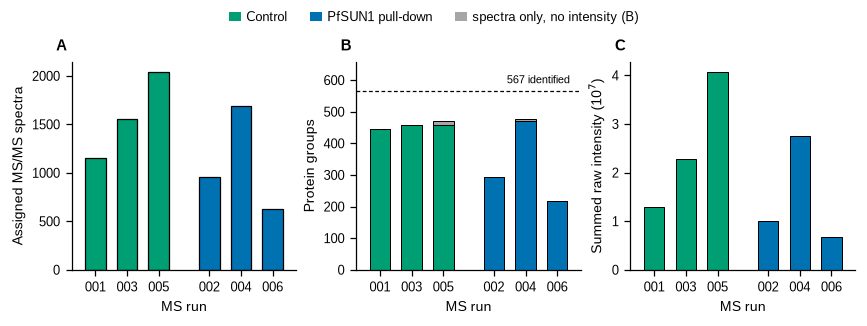

,condition,total_spectra,groups_with_spectra,groups_quantified,total_intensity,median_log2,missing_fraction
run,,,,,,,
001,control,1151,444,444,12917438.04,13.15,0.22
002,pulldown,959,295,294,10122222.36,13.40,0.48
003,control,1550,457,457,22708224.14,13.72,0.19
004,pulldown,1690,477,472,27493817.34,14.02,0.17
005,control,2042,470,458,40744675.25,13.82,0.19
006,pulldown,628,219,219,6796337.48,13.38,0.61


In [7]:
depth = (data.detection_summary(raw_intensity, CONDITION_OF)
         .rename(columns={"sample": "run", "quantified": "groups_quantified"}))
spectra = (saint.count_summary(counts, CONDITION_OF)
           .rename(columns={"sample": "run",
                            "proteins_with_spectra": "groups_with_spectra"}))

depth = depth.merge(
    spectra[["run", "total_spectra", "groups_with_spectra",
             "median_count_where_detected"]], on="run", validate="one_to_one")
depth["total_intensity"] = [float(raw_intensity[r].sum()) for r in depth["run"]]
depth["median_log2"] = [float(log2_raw[r].median()) for r in depth["run"]]

N_IDENTIFIED = len(workbook.annotation)
save_table(depth, "qc_measurement_depth")

fig, axes = figures.measurement_depth(depth, CONDITION_OF, COLOURS, N_IDENTIFIED,
                                      run_order=ORDERED_RUNS,
                                      condition_names=CONDITION_NAMES)
save_figure(fig, "01_measurement_depth", panel_axes=axes)
plt.show()

display(depth.set_index("run")[
    ["condition", "total_spectra", "groups_with_spectra", "groups_quantified",
     "total_intensity", "median_log2", "missing_fraction"]].round(2))


**Figure 1.  Measurement depth across runs**
The figure compares the number of assigned MS/MS spectra (A), identified and quantified protein groups (B), and total raw protein intensity (C) across the six runs. Measurement depth varies considerably. Run 005 has the most spectra (2,042), while run 004 has the most quantified protein groups. Run 006 has the fewest spectra (628) and quantified protein groups (219). Total intensity also varies strongly and is influenced by highly abundant proteins.

### 02.2 Missing measurements

Not every protein group is quantified in every run. We examine how often measurements are missing and whether this depends on protein abundance.

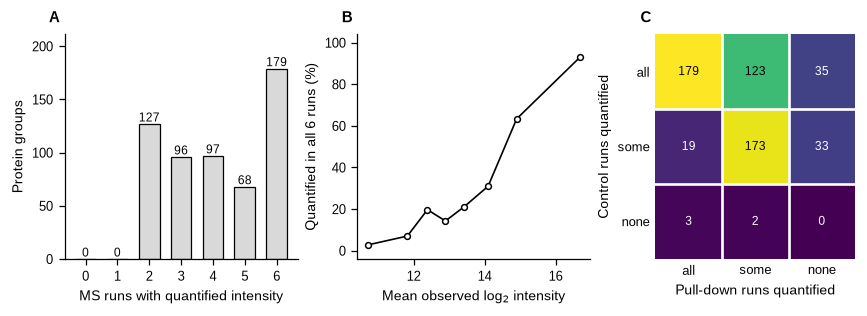

,detected_in_runs,protein_groups,mean_log2_of_observed,max_log2_of_observed
0,6 of 6,179,14.95,21.87
1,5 of 6,68,13.36,19.36
2,4 of 6,97,12.96,17.76
3,3 of 6,96,12.59,18.69
4,2 of 6,127,12.04,18.16


In [8]:
n_quantified = raw_intensity[RUNS].notna().sum(axis=1)
detection_frequency = (n_quantified.value_counts()
                       .reindex(range(len(RUNS) + 1), fill_value=0).sort_index()
                       .rename_axis("runs_detected")
                       .reset_index(name="protein_groups"))
detection_curve = data.detection_versus_abundance(log2_raw, RUNS)

# How completely each condition quantified each protein group: 'all' three runs
# of that condition, 'some' but not all, or 'none'.
pattern, _ = data.detection_pattern(raw_intensity, CONDITIONS)
PATTERN_ORDER = ["all", "some", "none"]
pattern_matrix = (pd.crosstab(pattern[CONTROL], pattern[PULLDOWN])
                  .reindex(index=PATTERN_ORDER, columns=PATTERN_ORDER,
                           fill_value=0))

for frame, name in ((detection_frequency, "qc_detection_frequency"),
                    (detection_curve, "qc_detection_versus_abundance"),
                    (pattern_matrix.rename_axis(f"{CONTROL}_runs")
                     .reset_index(), "qc_detection_pattern")):
    save_table(frame, name)

fig, axes = figures.missingness_overview(
    detection_frequency, detection_curve, pattern_matrix,
    runs_label=f"{len(RUNS)} runs",
    condition_labels={"rows": "Control", "columns": "Pull-down"},
    cmap=AGREEMENT_CMAP)
save_figure(fig, "02_missing_measurements", panel_axes=axes)
plt.show()

completeness, _ = data.missingness_by_detection(log2_raw, RUNS)
display(completeness)

**Figure 2. Missing measurements across runs**
Panel A shows how many runs each protein group was quantified in. Panel B relates detection frequency to protein abundance, while panel C compares detection between controls and pull-downs.
Only 179 of 567 protein groups (32%) are quantified in all six runs. More abundant proteins are generally detected more consistently. This is important for Section 04, where limma requires complete measurements and therefore tests only a subset of the data.

### 02.3 Agreement between MS runs
We compare protein intensity patterns between runs to assess how similar the measurements are within and between conditions. The comparison uses the same 89 parasite protein groups quantified in all six runs.

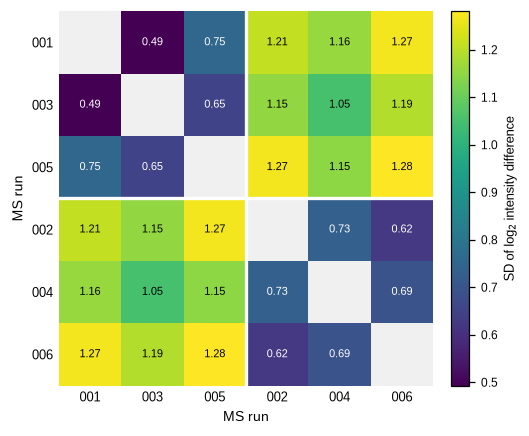

,count,min,max,mean
same_condition,,,,
False,9,1.052,1.281,1.192
True,6,0.493,0.753,0.658


In [9]:
# Species comes from the organism in each protein group's FASTA header.
headers = workbook.annotation["FASTA_HEADERS"].fillna("").astype(str)
IS_PARASITE = headers.str.contains("Plasmodium falciparum", regex=False)

complete = log2_raw.dropna()                       # quantified in all six runs
anchor_rows = complete.index[IS_PARASITE.reindex(complete.index).fillna(False)]
AGREEMENT_SET = log2_raw.loc[anchor_rows, RUNS]    # the 89, unnormalised

agreement = data.pair_disagreement(AGREEMENT_SET)
save_table(agreement, "qc_run_agreement")

fig, ax = figures.run_similarity_grid(
    agreement, ORDERED_RUNS, value=AGREEMENT_METRIC, label=AGREEMENT_LABEL,
    cmap=AGREEMENT_CMAP, figsize=AGREEMENT_SIZE, block_of=CONDITION_OF)
save_figure(fig, "03_run_similarity")
plt.show()

# The same numbers split by whether a pair sits inside one condition.
agreement["same_condition"] = [CONDITION_OF[a] == CONDITION_OF[b]
                               for a, b in zip(agreement["sample_a"],
                                               agreement["sample_b"])]
display(agreement.groupby("same_condition")[AGREEMENT_METRIC]
        .agg(["count", "min", "max", "mean"]).round(3))

**Figure 3. Agreement between MS runs** The heatmap shows the standard deviation of pairwise log₂ intensity differences. Lower values indicate more similar relative protein intensity patterns. Runs from the same condition are more similar (0.49–0.75) than runs from different conditions (1.05–1.28). The two conditions therefore show distinct protein intensity patterns, although variation remains between replicates.

### 02.4 Sample composition

The search database contains both human and P. falciparum proteins. We use the protein annotations to examine their relative contributions to each sample.

In [10]:
# Species, from the organism named in each protein group's FASTA header.
is_human = headers.str.contains("Homo sapiens", regex=False)
SOURCE = pd.Series("unassigned or other", index=headers.index)
SOURCE[IS_PARASITE & ~is_human] = "P. falciparum"
SOURCE[is_human & ~IS_PARASITE] = "human"
SOURCE[IS_PARASITE & is_human] = "mixed species"
SOURCE_ORDER = ["P. falciparum", "human", "mixed species", "unassigned or other"]

# Descriptive gene-symbol lists for the human groups. These say what a protein
# is, not how it got into the sample.
ERYTHROCYTE = {
    "SPTA1", "SPTB", "SLC4A1", "ANK1", "EPB41", "EPB42", "DMTN", "ADD1", "ADD2",
    "GYPA", "GYPB", "GYPC", "CA1", "CA2", "CAT", "PRDX2", "BLVRB", "ALAS2",
    "STOM", "AQP1", "RHCE", "RHAG", "HBA1", "HBB", "HBD", "HBG1", "HBG2"}
EPIDERMAL = {
    "DSG1", "DSG3", "DSC1", "DSC3", "JUP", "FLG", "FLG2", "HRNR", "KPRP", "DCD",
    "LGALS7", "LGALS7B", "SERPINB3", "SERPINB4", "SERPINB12", "TGM1", "TGM3",
    "XP32", "SBSN", "CASP14", "S100A7", "S100A8", "S100A9", "PI3", "LOR",
    "CSTA", "CDSN", "PKP1", "PKP3", "DSP", "EVPL", "PPL", "IVL", "CALML5",
    "SPRR1B", "SPRR2D", "SPRR2E", "CRNN", "TCHH", "ALOX12B"}

symbol = (workbook.annotation["GENE_NAMES"].fillna("").astype(str)
          .str.split(";").str[0].str.strip())

CLASS = SOURCE.copy()
human = SOURCE == "human"
CLASS[human] = "human, unassigned"
CLASS[human & symbol.isin(ERYTHROCYTE)] = "host erythrocyte"
CLASS[human & (symbol.isin(EPIDERMAL) | symbol.str.startswith("KRT"))] = "epidermal and sweat"
CLASS[human & (symbol.str.match(r"^IG[HKL]") | symbol.eq("JCHAIN"))] = "immunoglobulin"


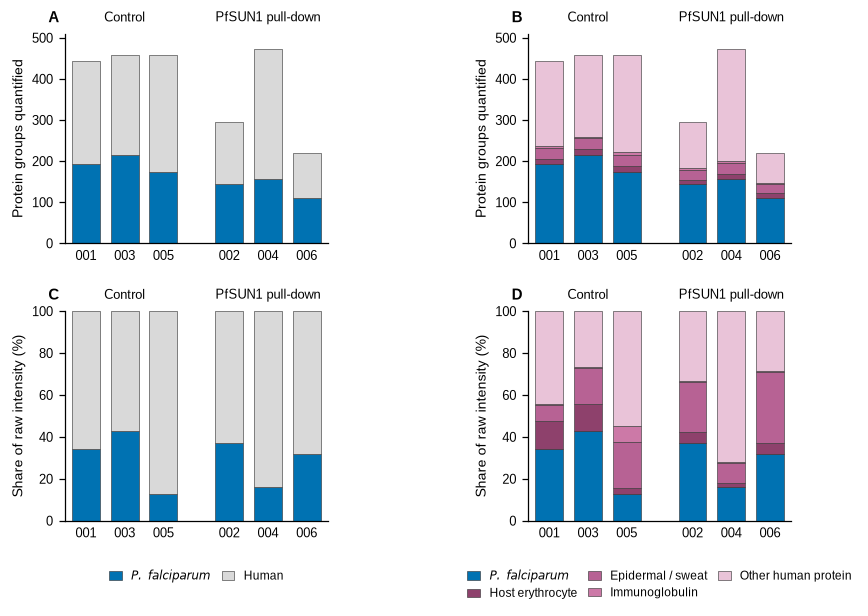

In [11]:
# Counts and intensity shares per run, at both levels of detail.
detected = raw_intensity[ORDERED_RUNS].notna()
run_total = raw_intensity[ORDERED_RUNS].sum(axis=0)
if (run_total <= 0).any():
    raise ValueError("a run has no positive intensity")

def per_run(group_of, order, weights=None):
    table = (weights if weights is not None else detected)
    out = table.groupby(group_of).sum().T.reindex(columns=order, fill_value=0)
    return out.div(run_total, axis=0) * 100 if weights is not None else out

source_counts = per_run(SOURCE, SOURCE_ORDER)
class_counts = per_run(CLASS, CLASS_ORDER)
source_percent = per_run(SOURCE, SOURCE_ORDER, raw_intensity[ORDERED_RUNS])
class_percent = per_run(CLASS, CLASS_ORDER, raw_intensity[ORDERED_RUNS])

# The two levels are computed independently, so these are real checks: every
# protein group is counted once and the two panels of a row must agree.
np.testing.assert_array_equal(source_counts.sum(axis=1), class_counts.sum(axis=1))
np.testing.assert_allclose(source_percent.sum(axis=1), 100)
np.testing.assert_allclose(class_percent.sum(axis=1), 100)
np.testing.assert_array_equal(source_counts["P. falciparum"],
                              class_counts["P. falciparum"])
np.testing.assert_allclose(source_percent["P. falciparum"],
                           class_percent["P. falciparum"])

for frame, name in ((source_counts, "qc_composition_counts_by_source"),
                    (class_counts, "qc_composition_counts_by_class"),
                    (source_percent, "qc_composition_percent_by_source"),
                    (class_percent, "qc_composition_percent_by_class")):
    save_table(frame.rename_axis("run").reset_index(), name)

fig, axes = figures.composition_across_runs(
    source_counts, class_counts, source_percent, class_percent,
    colours=CLASS_COLOURS, labels=CLASS_LABELS, condition_of=CONDITION_OF,
    condition_names=CONDITION_NAMES, figsize=COMPOSITION_SIZE,
    edge_colour=BAR_EDGE[0], edge_width=BAR_EDGE[1])
save_figure(fig, "04_composition_across_runs", panel_axes=axes)
plt.show()


**Figure 4. Protein composition across runs** Panels A and B show the numbers of quantified parasite and human protein groups, with human proteins further divided into annotated classes. Panels C and D show their contributions to total raw intensity. Parasite proteins account for 33–50% of quantified groups per run, but only 13–43% of the measured intensity. Human-associated signal also varies between samples, with particularly high immunoglobulin intensity in control 005 (7.3%). The protein classes are based on sequence and gene annotations. They do not establish how the proteins entered the samples.

### 02.5 Top intensity contributors
We identify which protein groups contribute most to the total measured signal.

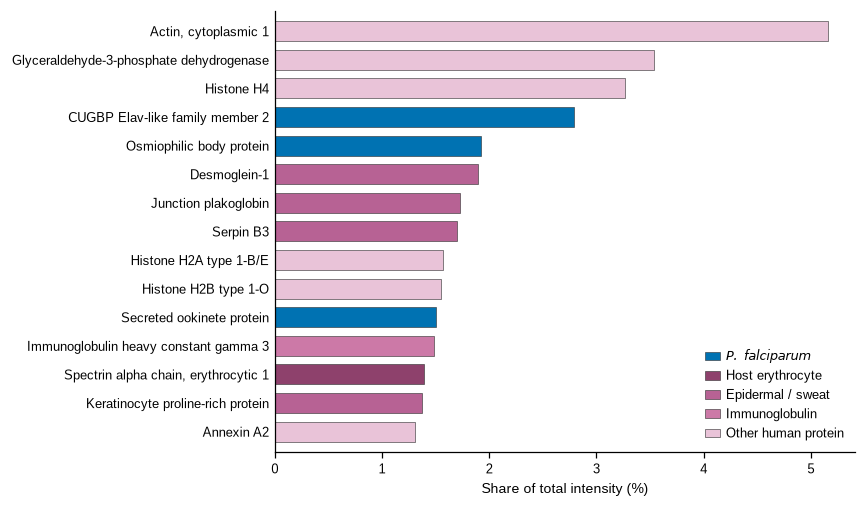

,gene,description,species,class,runs_quantified,share_of_total_intensity
UNIPROT_AC,,,,,,
P60709;P63261,ACTB,"Actin, cytoplasmic 1;Actin, cytoplasmic 2",human,"human, unassigned",6,5.155
P04406,GAPDH,Glyceraldehyde-3-phosphate dehydrogenase,human,"human, unassigned",6,3.535
P62805,H4C1,Histone H4,human,"human, unassigned",6,3.269
Q8ILZ7,PF3D7_1409800,"CUGBP Elav-like family member 2, putative",P. falciparum,P. falciparum,6,2.794
Q8I4T3,PF3D7_1250100,Osmiophilic body protein,P. falciparum,P. falciparum,6,1.923
Q02413,DSG1,Desmoglein-1,human,epidermal and sweat,6,1.890
P14923,JUP,Junction plakoglobin,human,epidermal and sweat,6,1.730
P29508,SERPINB3,Serpin B3,human,epidermal and sweat,6,1.695
P04908;P0C0S8;P20671;Q16777;Q6FI13;Q7L7L0;Q93077;Q96KK5;Q99878;Q9BTM1,H2AC4,Histone H2A type 1-B/E;Histone H2A type 1;Hist...,human,"human, unassigned",6,1.567


In [12]:
# Name each group by what it is: a PF3D7 number says nothing on a figure, and
# the "putative" hedge belongs in the table rather than the label.
description = (workbook.annotation["PROTEIN_DESCRIPTIONS"].astype(str)
               .str.split(";").str[0]
               .str.replace(r",?\s*putative$", "", regex=True).str.strip())
fallback = symbol.where(symbol.ne("nan") & symbol.ne(""),
                        workbook.annotation["UNIPROT_AC"])
label = description.mask(
    description.str.contains("uncharacterized", case=False)
    | description.isin(["nan", ""]), fallback).str.slice(0, 45)

share_of_all = raw_intensity.sum(axis=1) / raw_intensity.sum().sum() * 100

contributors = (pd.DataFrame({
        "UNIPROT_AC": workbook.annotation["UNIPROT_AC"],
        "gene": symbol,
        "description": workbook.annotation["PROTEIN_DESCRIPTIONS"],
        "species": SOURCE,
        "class": CLASS,
        "runs_quantified": n_quantified,
        "share_of_total_intensity": share_of_all.round(3)})
    .sort_values("share_of_total_intensity", ascending=False))
save_table(contributors, "qc_protein_intensity_share")

fig, ax = figures.top_contributors(
    raw_intensity, CLASS, label, CLASS_COLOURS, top_n=TOP_CONTRIBUTORS,
    class_order=CLASS_ORDER, class_labels=CLASS_LABELS,
    edge_colour=BAR_EDGE[0], edge_width=BAR_EDGE[1])
save_figure(fig, "05_top_contributors")
plt.show()

display(contributors.head(TOP_CONTRIBUTORS).set_index("UNIPROT_AC"))

**Figure 5. Most abundant protein groups** The figure shows the 15 protein groups with the largest summed raw intensities across all six runs, coloured by protein class. These 15 groups account for 32.2% of the total intensity. The three largest contributors are human-associated actin, GAPDH and histone H4. The highest-intensity parasite protein group ranks fourth. Because intensities are summed across runs, samples with higher total signal contribute more to this ranking.

---

## 03. Bait recovery
Before identifying potential interaction partners, we check whether PfSUN1 was recovered in the pull-downs compared with the controls.

In [13]:
bait = data.bait_recovery(log2_raw, BAIT_ROW, CONDITION_OF)
bait["spectral_counts"] = counts.loc[BAIT_ROW].to_numpy()
bait["identification_qvalue"] = (
    workbook.evidence("Identification Qvalue").loc[BAIT_ROW].to_numpy())

bait_peptides = peptides_sheet[peptides_sheet["PROTEIN_UNIPROT_AC"] == BAIT]
run_of = {f"{run}_FR002_G26": run for run in RUNS}
measured = (bait_peptides[list(run_of)].rename(columns=run_of).notna().sum()
            .reindex(bait["sample"]).to_numpy())
bait["peptides_measured"] = measured
bait["peptides_total"] = len(bait_peptides)

save_table(bait, "qc_bait_recovery")
save_table(bait_peptides[["PEPTIDE_SEQ"] + list(run_of)].rename(columns=run_of),
           "qc_bait_peptides")
display(bait.set_index("sample"))

,condition,bait_log2_intensity,rank_by_intensity,of_n_quantified,percent_of_sample_signal,spectral_counts,identification_qvalue,peptides_measured,peptides_total
sample,,,,,,,,,
001,control,NaN,NaN,444,NaN,0,NaN,0,14
002,pulldown,17.112,17.0,294,1.40,14,0.000000,13,14
003,control,12.186,363.0,457,0.02,1,0.003902,1,14
004,pulldown,17.723,29.0,472,0.79,15,0.000000,14,14
005,control,NaN,NaN,458,NaN,0,NaN,0,14
006,pulldown,16.325,20.0,219,1.21,14,0.000000,13,14


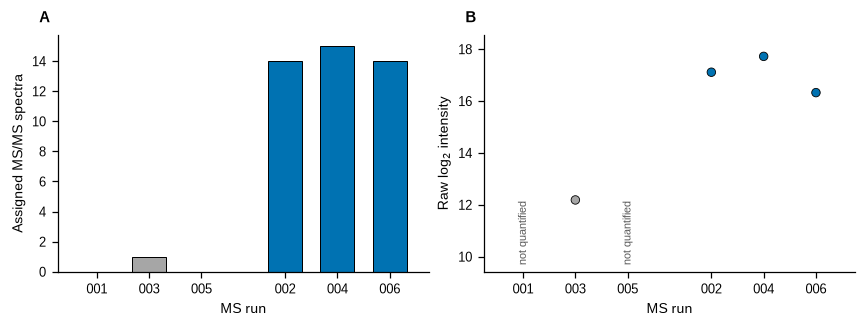

In [14]:
# Grey for the controls in this figure rather than the usual green: it is about
# the bait's own evidence, and the controls are the background it is read against.
BAIT_RUN_COLOURS = {CONTROL: figures.BACKGROUND_RAMP[2],
                    PULLDOWN: figures.PULLDOWN_COLOUR}

fig, axes = figures.bait_recovery(bait, BAIT_RUN_COLOURS, run_order=ORDERED_RUNS)
save_figure(fig, "06_bait_recovery", panel_axes=axes)
plt.show()

**Figure 6. PfSUN1 recovery across runs** Panel A shows the MS/MS spectra assigned to PfSUN1 in each run, panel B its raw log₂ intensity. A zero count means that no spectrum was assigned to PfSUN1 in that run, and a run with too little evidence to quantify is marked as not quantified rather than shown as zero. PfSUN1 was recovered in all three pull-downs, with 14, 15 and 14 spectra, and only in one control, run 003, with a single spectrum. Controls are grey, pull-downs blue.

In [15]:
n_control = log2_raw[CONDITIONS[CONTROL]].notna().sum(axis=1)
n_pulldown = log2_raw[CONDITIONS[PULLDOWN]].notna().sum(axis=1)
n_observed = {CONTROL: n_control, PULLDOWN: n_pulldown}   # reused in section 04
mean_control = log2_raw[CONDITIONS[CONTROL]].mean(axis=1)    # observed runs only
mean_pulldown = log2_raw[CONDITIONS[PULLDOWN]].mean(axis=1)
difference = mean_pulldown - mean_control

# Eligible: every pull-down quantified, and at least one control to compare with.
rankable = (IS_PARASITE & (n_pulldown == len(CONDITIONS[PULLDOWN]))
            & (n_control >= MIN_CONTROLS_TO_RANK))
# Detected in the pull-downs but never in a control: no difference exists.
no_control = IS_PARASITE & (n_pulldown >= MIN_PULLDOWN_RUNS) & (n_control == 0)

reason = pd.Series("not quantified in every pull-down", index=log2_raw.index)
reason[rankable] = "ranked"
reason[no_control] = "no control measurement, cannot be ranked"
reason[~IS_PARASITE] = "not a P. falciparum protein group"

# Median equalisation on the parasite groups quantified in every run. It is
# computed here because the table below reports the normalised difference
# alongside the raw one; section 04.1 explains the choice and reuses it.
ANCHOR = IS_PARASITE & (n_control + n_pulldown == len(RUNS))
normalised, offsets = processing.median_equalise(log2_raw, RUNS, rows=ANCHOR)
normalised_difference = (normalised[CONDITIONS[PULLDOWN]].mean(axis=1)
                         - normalised[CONDITIONS[CONTROL]].mean(axis=1))

recovery = pd.DataFrame({
    "UNIPROT_AC": workbook.annotation["UNIPROT_AC"], "gene": symbol,
    "description": workbook.annotation["PROTEIN_DESCRIPTIONS"],
    "species": SOURCE, "n_control": n_control, "n_pulldown": n_pulldown,
    "mean_log2_control": mean_control.round(3),
    "mean_log2_pulldown": mean_pulldown.round(3),
    "difference_log2_raw": difference.round(3),
    "difference_log2_normalised": normalised_difference.round(3),
    "spectra_control": counts[CONDITIONS[CONTROL]].sum(axis=1).astype(int),
    "spectra_pulldown": counts[CONDITIONS[PULLDOWN]].sum(axis=1).astype(int),
    "is_bait": log2_raw.index == BAIT_ROW,
    "ranking": reason})
# Unrankable groups must not carry a difference, even an arithmetic one.
recovery.loc[~rankable, ["difference_log2_raw", "difference_log2_normalised"]] = np.nan
recovery = recovery.sort_values("difference_log2_raw", ascending=False)
save_table(recovery, "qc_ranked_difference_vs_control")

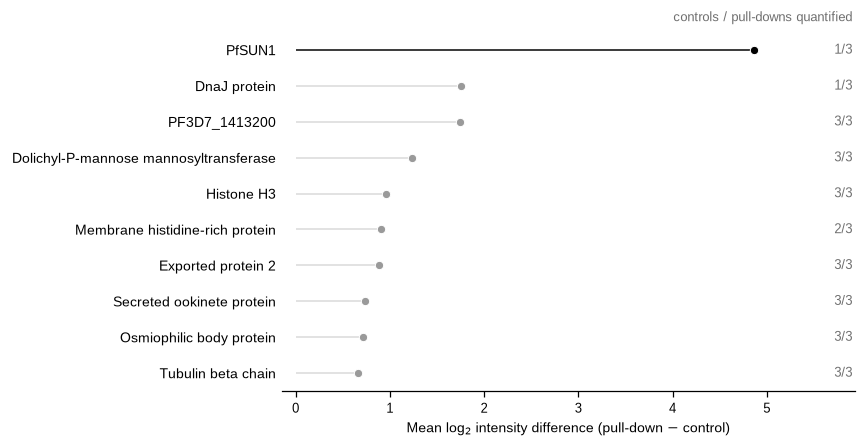

,gene,description,n_control,n_pulldown,mean_log2_control,mean_log2_pulldown,difference_log2_raw,difference_log2_normalised
537,PF3D7_1215100,Uncharacterized protein,1,3,12.186,17.053,4.867,6.423
447,PF3D7_0629200,"DnaJ protein, putative",1,3,11.063,12.814,1.750,3.306
117,PF3D7_1413200,Uncharacterized protein,3,3,15.105,16.850,1.745,2.573
395,PF3D7_1010700,Dolichyl-phosphate-mannose protein mannosyltra...,3,3,11.890,13.123,1.233,2.061
274,PF3D7_0610400,Histone H3,3,3,12.289,13.249,0.960,1.788
323,PF3D7_1370300,Membrane associated histidine-rich protein;Mem...,2,3,12.324,13.232,0.908,1.969
268,PF3D7_1471100,Exported protein 2,3,3,13.141,14.022,0.881,1.709
13,PF3D7_0513700,"Secreted ookinete protein, putative",3,3,17.688,18.426,0.738,1.566
7,PF3D7_1250100,Osmiophilic body protein,3,3,18.073,18.791,0.719,1.547
128,PF3D7_1008700,Tubulin beta chain,3,3,15.091,15.754,0.662,1.491


,gene,description,n_control,n_pulldown,spectra_control,spectra_pulldown,mean_log2_pulldown
529,PF3D7_1247800,Dipeptidyl aminopeptidase 2,0,3,0,10,13.859
533,PF3D7_0503800,60S ribosomal protein L31,0,3,0,3,10.786
550,PF3D7_1469200,"Shewanella-like protein phosphatase 1, putative",0,3,0,3,10.681
448,PF3D7_1426300,"Dynein-associated protein, putative",0,2,0,2,9.716


In [16]:
# The workbook has no name for the bait, so it carries ours on the figure.
# A few descriptions are too long for a row and are given a short form here
# rather than being cut mid-phrase.
FIGURE_NAMES = {"PF3D7_1215100": BAIT_NAME_LONG,
                "PF3D7_1010700": "Dolichyl-P-mannose mannosyltransferase",
                "PF3D7_1370300": "Membrane histidine-rich protein"}
plot_label = pd.Series(
    [FIGURE_NAMES.get(symbol.at[r], figures.shorten_name(label.at[r], 42))
     for r in label.index], index=label.index)

top = difference[rankable].nlargest(TOP_N_RECOVERY).index

fig, ax = plt.subplots(figsize=BAIT_RECOVERY_SIZE)
figures.enrichment_ranking(
    {"recovery": difference[top]}, [plot_label[r] for r in top],
    colours={"recovery": figures.BAIT_COLOUR},
    highlight_only=[r == BAIT_ROW for r in top], series_label=False,
    x_label="Mean log$_2$ intensity difference (pull-down $-$ control)",
    annotations=[f"{n_control[r]}/{n_pulldown[r]}" for r in top],
    annotation_header="controls / pull-downs quantified",
    annotation_size=7.5, ax=ax)
ax.tick_params(axis="y", labelsize=8.5)
ax.xaxis.label.set_size(8.5)
save_figure(fig, "06b_top10_recovery")
plt.show()

display(recovery.loc[top, ["gene", "description", "n_control", "n_pulldown",
                           "mean_log2_control", "mean_log2_pulldown",
                           "difference_log2_raw", "difference_log2_normalised"]])

# The groups the ranking cannot include, as a table: no control value means no
# difference, so they have no place on the axis above.
no_control_rows = mean_pulldown[no_control].sort_values(ascending=False).index
display(recovery.loc[no_control_rows,
                     ["gene", "description", "n_control", "n_pulldown",
                      "spectra_control", "spectra_pulldown",
                      "mean_log2_pulldown"]])

**Figure 6b. Parasite protein recovery relative to controls** The plot ranks the ten *P. falciparum* protein groups with the largest mean log₂ intensity difference between the pull-downs and the controls, with the number of controls and pull-downs each group was quantified in beside it. PfSUN1 ranks first at +4.87 log₂, but that difference rests on a single quantified control.

---

## 04. Differential recovery

We compare protein intensities between PfSUN1 pull-downs and controls to identify proteins that are consistently enriched or depleted. Two statistical methods are used: limma and proDA. They differ mainly in how they handle missing measurements and estimate uncertainty.

### 04.1 Normalisation

Protein intensities can vary between MS runs for reasons unrelated to the proteins being studied. Normalisation attempts to reduce these differences before comparing conditions.

Here, we use 89 P. falciparum protein groups quantified in all six runs as a reference. Their median intensities are aligned across samples, assuming that their overall abundance should remain similar.

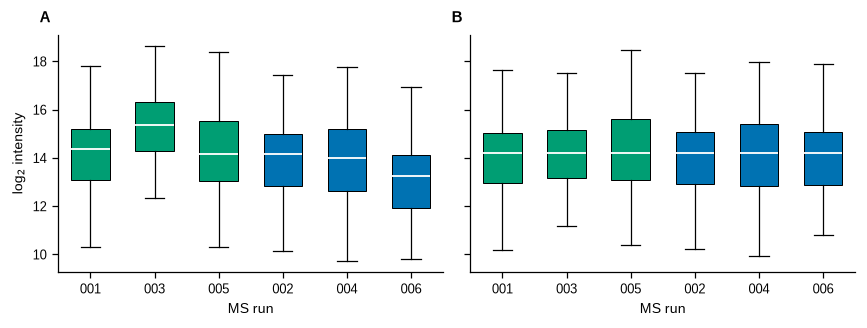

,run,condition,median_all_groups,median_anchor,offset_applied
0,001,control,13.150,14.371,-0.152
1,002,pulldown,13.403,14.155,0.064
2,003,control,13.720,15.361,-1.142
3,004,pulldown,14.021,14.007,0.212
4,005,control,13.823,14.167,0.052
5,006,pulldown,13.379,13.253,0.966


In [17]:
# ANCHOR, the normalised matrix and the offsets were computed in section 03,
# where the ranking table already needed them. This cell shows what they did.
offset_table = pd.DataFrame({
    "run": RUNS, "condition": [CONDITION_OF[r] for r in RUNS],
    "median_all_groups": log2_raw[RUNS].median().round(3).to_numpy(),
    "median_anchor": log2_raw.loc[ANCHOR, RUNS].median().round(3).to_numpy(),
    "offset_applied": offsets[RUNS].round(3).to_numpy()})
save_table(offset_table, "normalisation_offsets")

anchor_table = pd.DataFrame({
    "UNIPROT_AC": workbook.annotation.loc[ANCHOR, "UNIPROT_AC"],
    "gene": symbol[ANCHOR], "description": workbook.annotation.loc[ANCHOR, "PROTEIN_DESCRIPTIONS"]})
for run in RUNS:
    anchor_table[f"log2_{run}"] = log2_raw.loc[ANCHOR, run].round(3)
save_table(anchor_table, "normalisation_anchor_proteins")

fig, axes = figures.normalisation(log2_raw.loc[ANCHOR], normalised.loc[ANCHOR],
                                  ORDERED_RUNS, CONDITION_OF, COLOURS)
fig.set_size_inches(*NORMALISATION_SIZE)
save_figure(fig, "07_normalisation", panel_axes=axes)
plt.show()

display(offset_table)

**Figure 7. Protein intensities before and after normalisation** The figure shows the intensity distributions of the 89 reference protein groups before (A) and after (B) normalisation. Normalisation reduces differences between runs and shifts the pull-down intensities by approximately +0.83 log₂ relative to controls. The same 89 proteins are also used for the statistical testing in Section 04, so the correction may remove genuine differences along with technical variation.

### 04.2 Differential recovery analysis

We use limma to compare the 89 parasite protein groups quantified in every run. proDA also includes proteins with missing intensity measurements, allowing 223 parasite groups to be tested.

In [18]:
RSCRIPT = differential.find_rscript()
TESTABLE, exclusion = processing.complete_cases(
    log2_raw, CONDITIONS, min_per_condition=len(CONDITIONS[CONTROL]))

results = differential.limma_contrast(normalised.loc[ANCHOR, RUNS], CONDITION_OF,
                                      PULLDOWN, CONTROL, rscript=RSCRIPT)
unnormalised = differential.limma_contrast(log2_raw.loc[ANCHOR, RUNS], CONDITION_OF,
                                           PULLDOWN, CONTROL, rscript=RSCRIPT)
enriched = results[(results["p_adjusted"] <= FDR_CUTOFF) & (results["log2FC"] > 0)]
depleted = results[(results["p_adjusted"] <= FDR_CUTOFF) & (results["log2FC"] < 0)]

differential_table = pd.DataFrame({
    "UNIPROT_AC": workbook.annotation["UNIPROT_AC"], "gene": symbol,
    "description": workbook.annotation["PROTEIN_DESCRIPTIONS"], "species": SOURCE})
for condition, group in CONDITIONS.items():
    differential_table[f"n_{condition}"] = n_observed[condition]
    differential_table[f"mean_log2_{condition}"] = normalised[group].mean(axis=1).round(3)
    differential_table[f"spectra_{condition}"] = counts[group].sum(axis=1).astype(int)
for column in ("log2FC", "avg_log2", "t", "p_value", "p_adjusted"):
    differential_table[column] = results[column]
differential_table["log2FC_unnormalised"] = unnormalised["log2FC"]
differential_table["tested"] = differential_table.index.isin(results.index)
differential_table["exclusion_reason"] = np.where(
    differential_table["tested"], "",
    np.where(~IS_PARASITE, "not a P. falciparum protein group", exclusion))
save_table(differential_table, "differential_recovery")

print(f"{len(results)} of {int(IS_PARASITE.sum())} parasite groups tested; "
      f"{len(enriched)} enriched and {len(depleted)} depleted at BH <= {FDR_CUTOFF}. "
      f"{results.attrs['limma_message'].split(',', 1)[1].strip()}")

89 of 223 parasite groups tested; 13 enriched and 16 depleted at BH <= 0.05. contrast pulldown - control, residual df 4, prior df 8.288


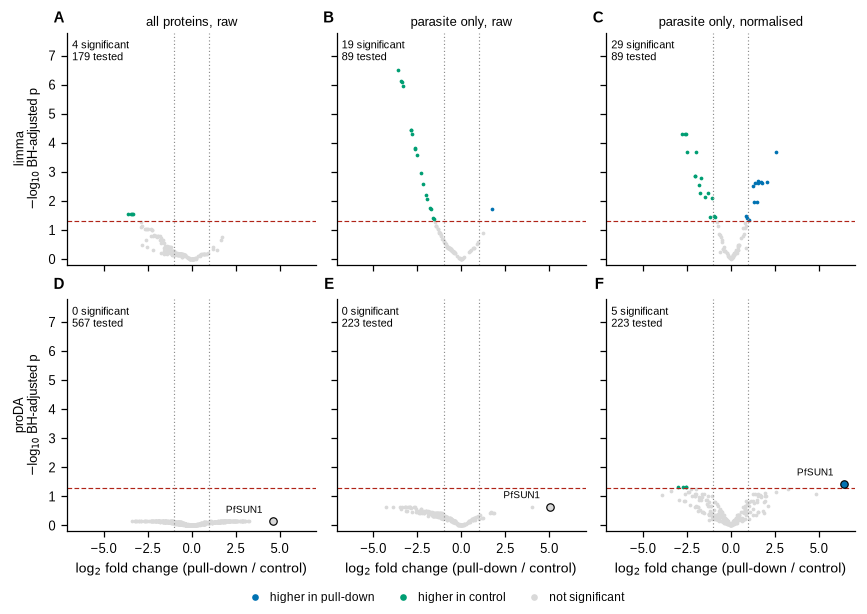

,method,population,tested,significant,enriched,depleted
0,limma,"all proteins, raw",179,4,0,4
1,limma,"parasite only, raw",89,19,1,18
2,limma,"parasite only, normalised",89,29,13,16
3,proDA,"all proteins, raw",567,0,0,0
4,proDA,"parasite only, raw",223,0,0,0
5,proDA,"parasite only, normalised",223,5,1,4


In [19]:
# The same contrast under six analyses, all fitted here from the workbook.
# limma needs complete cases; proDA models a missing value with a dropout curve
# and so keeps every protein, including the bait.
METHODS = ["limma", "proDA"]
POPULATIONS = {"all proteins, raw": (pd.Series(True, index=log2_raw.index), False),
               "parasite only, raw": (IS_PARASITE, False),
               "parasite only, normalised": (IS_PARASITE, True)}

# Two of the six are the reference analysis and its unnormalised counterpart,
# fitted in section 04.2. Panel C is that object itself, not a repeat of it.
ALREADY_FITTED = {("limma", "parasite only, normalised"): results,
                  ("limma", "parasite only, raw"): unnormalised}

six = {}
for method in METHODS:
    for population, (rows, use_normalised) in POPULATIONS.items():
        fit = ALREADY_FITTED.get((method, population))
        if fit is None:
            matrix = normalised if use_normalised else log2_raw
            fit = (differential.limma_contrast(matrix.loc[rows & TESTABLE, RUNS],
                                               CONDITION_OF, PULLDOWN, CONTROL,
                                               rscript=RSCRIPT) if method == "limma"
                   else differential.proda_contrast(matrix.loc[rows, RUNS],
                                                    CONDITION_OF, PULLDOWN, CONTROL,
                                                    rscript=RSCRIPT))
        six[(method, population)] = fit
        save_table(fit.reset_index(names="row"),
                   f"diff_{method}_{population.replace(', ', '_').replace(' ', '_')}")

proda_norm = six[("proDA", "parasite only, normalised")]

# Only the bait is named: it is the one protein whose position every panel
# should be judged against, and it is absent from the two limma panels that
# require complete cases.
fig, axes = figures.volcano_grid(
    six, METHODS, list(POPULATIONS), fdr_cutoff=FDR_CUTOFF,
    labels=pd.Series({BAIT_ROW: BAIT_NAME_LONG}), label_rows=[BAIT_ROW])
save_figure(fig, "08_differential_recovery")   # volcano_grid letters its own panels
plt.show()

method_comparison = pd.DataFrame([
    {"method": method, "population": population, "tested": len(fit),
     "significant": int((fit["p_adjusted"] <= FDR_CUTOFF).sum()),
     "enriched": int(((fit["p_adjusted"] <= FDR_CUTOFF) & (fit["log2FC"] > 0)).sum()),
     "depleted": int(((fit["p_adjusted"] <= FDR_CUTOFF) & (fit["log2FC"] < 0)).sum())}
    for (method, population), fit in six.items()])
save_table(method_comparison, "method_comparison")
display(method_comparison)

**Figure 8. Differential recovery using limma and proDA** The six volcano plots compare the two statistical methods (rows) across three analyses (columns): all proteins without normalisation, parasite proteins without normalisation, and parasite proteins after normalisation. Each point represents a protein group. Positive log₂ fold changes indicate higher intensity in the pull-downs. The horizontal dashed line marks the significance threshold of BH-adjusted p ≤ 0.05. After normalisation, limma identifies 13 enriched and 16 depleted parasite protein groups. Without normalisation, only one is enriched and 18 are depleted. proDA identifies five significant parasite groups after normalisation, including PfSUN1, and none using raw intensities. The result therefore depends on the method and on the number of proteins tested, which affects the adjusted p-values. The table below lists the 13 proteins enriched by normalised limma, alongside their proDA results. None reaches the significance threshold under proDA. These proteins remain candidates for further investigation rather than confirmed interaction partners.

In [20]:
# The enriched groups of the reference analysis, with what each method and the
# unnormalised fit say about them. Exported as the candidate list of section 04.
candidates = differential_table.loc[enriched.index, [
    "UNIPROT_AC", "gene", "description", "n_control", "n_pulldown",
    "spectra_control", "spectra_pulldown", "log2FC", "log2FC_unnormalised",
    "p_adjusted"]].copy()
candidates["log2FC_proDA"] = proda_norm["log2FC"].reindex(enriched.index).round(3)
candidates["BH_proDA"] = proda_norm["p_adjusted"].reindex(enriched.index).round(4)
candidates["significant_under_proDA"] = candidates["BH_proDA"] <= FDR_CUTOFF
candidates = candidates.sort_values("log2FC", ascending=False)
save_table(candidates, "candidate_proteins")

display(candidates[["gene", "log2FC", "p_adjusted", "log2FC_proDA", "BH_proDA",
                    "significant_under_proDA"]])

,gene,log2FC,p_adjusted,log2FC_proDA,BH_proDA,significant_under_proDA
117,PF3D7_1413200,2.572946,0.000213,2.559,0.0702,False
395,PF3D7_1010700,2.060746,0.002192,1.941,0.0966,False
274,PF3D7_0610400,1.788247,0.002444,1.710,0.0966,False
268,PF3D7_1471100,1.709197,0.002192,1.661,0.0917,False
13,PF3D7_0513700,1.565970,0.002052,1.570,0.0833,False
7,PF3D7_1250100,1.546932,0.002389,1.552,0.0884,False
128,PF3D7_1008700,1.490526,0.010968,1.471,0.1562,False
34,PF3D7_1116800,1.360509,0.002389,1.362,0.0833,False
180,PF3D7_0821700,1.303572,0.010968,1.268,0.1420,False
144,PF3D7_0422400,1.286868,0.003046,1.278,0.0833,False


---

## 05. Interaction evidence
SAINTexpress uses spectral counts to identify proteins that are preferentially recovered in PfSUN1 pull-downs compared with controls. It considers the counts across individual runs and estimates interaction confidence using the SAINT score and Bayesian false discovery rate (BFDR). Unlike intensity-based analyses, SAINTexpress can use zero spectral counts. A zero means that no spectra were identified for that protein in a particular run, although the protein may still be present.

In [21]:
SAINT_BINARY = saint.find_saintexpress(TOOL_CACHE)

# Verify the program against its own documented example before our data.
# RUVBL1 and RUVBL2 are the proteins the TIP49 dataset is named after.
tip49 = saint.reference_example(SAINT_BINARY)
reference_top = set(tip49[tip49["Bait"] == "ACTR5"].nlargest(2, "SaintScore")["Prey"])
if reference_top != {"RUVBL1", "RUVBL2"}:
    raise AssertionError(f"TIP49 example did not reproduce: {sorted(reference_top)}")

saint.validate_counts(counts)      # raises on a non-integer or negative count

# Every protein group becomes one prey, identified by its first accession and
# named by its gene. SAINTexpress-spc stores a prey length but never reads it
# back, so the two-column prey file it also accepts is written here and no
# protein sequences are needed.
prey_mapping = saint.prey_table(workbook.annotation["UNIPROT_AC"],
                                workbook.annotation["GENE_NAMES"])

if len(prey_mapping) != len(workbook.annotation):
    raise ValueError("a protein group did not become a prey")
if prey_mapping["prey_id"].duplicated().any():
    raise ValueError("prey identifiers are not unique")

SAINT_BAITS = {**{run: CONTROL for run in CONDITIONS[CONTROL]},
               **{run: BAIT_NAME for run in CONDITIONS[PULLDOWN]}}
tables = saint.saint_tables(counts, prey_mapping, SAINT_BAITS, CONDITIONS[CONTROL])

# The counts SAINTexpress receives must be the counts the workbook holds. Only
# non-zero counts are written; SAINTexpress reads an absent row as a zero.
written = (tables["inter"].pivot(index="prey_id", columns="ip_id", values="count")
           .reindex(index=prey_mapping["prey_id"], columns=RUNS).fillna(0).to_numpy())
if not np.array_equal(written, counts[RUNS].fillna(0).to_numpy()):
    raise AssertionError("the counts written to inter.dat differ from the workbook")

print(f"{saint.version(SAINT_BINARY)}, SHA-256 {data.sha256(SAINT_BINARY)[:16]}…, "
      "reproduces its own TIP49 example")
print(f"{len(prey_mapping)} preys, each with a unique identifier and a gene name; "
      f"{int((prey_mapping['n_accessions'] > 1).sum())} groups hold more than one "
      "accession and are represented by the first")

SAINT express version 3.6.1, SHA-256 03b0d5c929bf9634…, reproduces its own TIP49 example
567 preys, each with a length and a unique identifier; 43 groups hold more than one accession and are represented by the first


In [22]:
SAINT_RUN = OUTPUT / "saint"          # SAINTexpress input and output files
saint_result = saint.run(tables, SAINT_BINARY, workdir=SAINT_RUN)
scores = saint.tidy_scores(saint_result, prey_mapping, [BAIT_NAME])

input_summary = pd.DataFrame(
    [{"file": f.name, "bytes": f.stat().st_size, "sha256": data.sha256(f)}
     for f in sorted(SAINT_RUN.iterdir())]
    + [{"file": "SAINTexpress-spc", "bytes": SAINT_BINARY.stat().st_size,
        "sha256": data.sha256(SAINT_BINARY)}])
input_summary["detail"] = [
    f"{len(tables['inter']):,} rows" if f == "inter.dat" else
    f"{len(tables['prey']):,} preys" if f == "prey.dat" else
    f"{len(tables['bait'])} runs" if f == "bait.dat" else
    f"{len(saint_result):,} scored pairs" if f == "list.txt" else
    saint.version(SAINT_BINARY) for f in input_summary["file"]]
save_table(input_summary, "saint_input_summary")

saint_table = pd.DataFrame({
    "gene": symbol, "description": workbook.annotation["PROTEIN_DESCRIPTIONS"],
    "species": SOURCE,
    "avg_spec": scores[f"avg_spec_{BAIT_NAME}"],
    "control_counts": scores[f"control_counts_{BAIT_NAME}"],
    "fold_change": scores[f"fold_change_{BAIT_NAME}"],
    "saint_score": scores[f"saint_score_{BAIT_NAME}"],
    "bfdr": scores[f"bfdr_{BAIT_NAME}"]})
# SAINTexpress writes a row only for preys with evidence in a test IP, so a
# group seen only in the controls gets no score. That is not a score of zero
# and it is labelled rather than left blank.
seen_in_pulldown = (counts[CONDITIONS[PULLDOWN]] > 0).any(axis=1)
saint_table["saint_status"] = np.where(
    saint_table["saint_score"].notna(), "scored",
    "not scored: no spectra in any pull-down")
if not (saint_table["saint_score"].notna() == seen_in_pulldown).all():
    raise AssertionError("unscored preys are not exactly those absent from the pull-downs")
save_table(saint_table.reset_index(names="row"), "saint_scores")

scored = saint_table["saint_score"].notna()
passing = saint_table["bfdr"] <= BFDR_CUTOFF
print(f"{int(scored.sum())} of {len(saint_table)} groups scored, "
      f"{int((~scored).sum())} not scored for want of any pull-down spectrum; "
      f"{int((saint_table['saint_score'] == 0).sum())} score exactly 0.00")
print(f"BFDR <= {BFDR_CUTOFF}: {int(passing.sum())}   BFDR <= 0.01: "
      f"{int((saint_table['bfdr'] <= 0.01).sum())}   score >= 0.5: "
      f"{int((saint_table['saint_score'] >= 0.5).sum())}")
display(saint_table[passing])

501 of 567 groups scored, 66 not scored for want of any pull-down spectrum; 426 score exactly 0.00
BFDR <= 0.05: 2   BFDR <= 0.01: 2   score >= 0.5: 3


,gene,description,species,avg_spec,control_counts,fold_change,saint_score,bfdr,saint_status
529,PF3D7_1247800,Dipeptidyl aminopeptidase 2,P. falciparum,3.33,0|0|0,33.33,0.79,0.0,scored
537,PF3D7_1215100,Uncharacterized protein,P. falciparum,14.33,0|1|0,43.00,1.00,0.0,scored


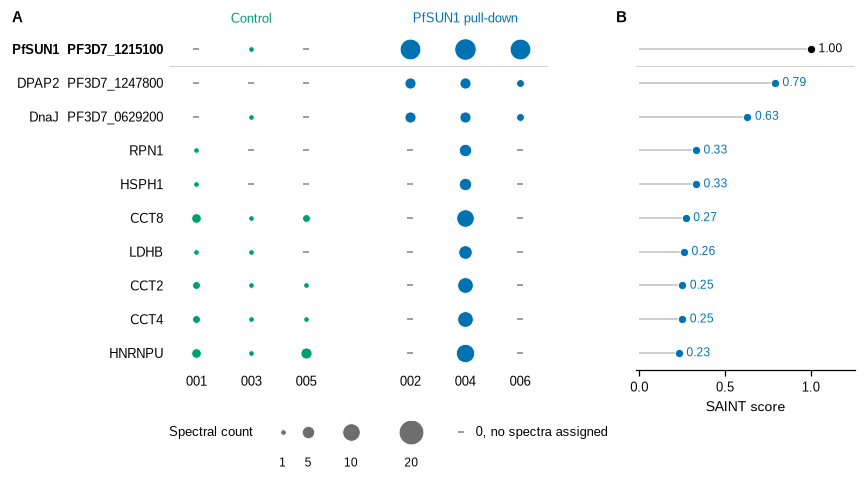

,gene,species,001,003,005,002,004,006,saint_score,bfdr
537,PF3D7_1215100,P. falciparum,0,1,0,14,15,14,1.00,0.00
529,PF3D7_1247800,P. falciparum,0,0,0,4,4,2,0.79,0.00
447,PF3D7_0629200,P. falciparum,0,1,0,4,4,2,0.63,0.11
281,RPN1,human,1,0,0,0,5,0,0.33,0.20
412,HSPH1,human,1,0,0,0,5,0,0.33,0.20
162,CCT8,human,3,1,2,0,10,0,0.27,0.38
133,LDHB,human,1,1,0,0,6,0,0.26,0.44
150,CCT2,human,2,1,1,0,8,0,0.25,0.48
178,CCT4,human,2,1,1,0,8,0,0.25,0.48
199,HNRNPU,human,3,1,4,0,11,0,0.23,0.57


In [23]:
# Short names for the row labels; the workbook's own descriptions are too
# long for a row. Human preys already carry a gene symbol and need no entry.
SHORT_NAME = {
    "PF3D7_1215100": BAIT_NAME_LONG,      "PF3D7_1247800": "DPAP2",
    "PF3D7_0629200": "DnaJ",              "PF3D7_1325200": "oxidoreductase",
    "PF3D7_1226100": "HAD hydrolase",     "PF3D7_1010700": "mannosyltransferase",
    "PF3D7_0513700": "ookinete protein",  "PF3D7_1413200": "uncharacterised",
    "PF3D7_0610400": "histone H3",        "PF3D7_1471100": "EXP2",
    "PF3D7_1431700": "60S L14",           "PF3D7_0912400": "alkaline phosphatase",
    "PF3D7_1008700": "tubulin beta",      "PF3D7_1409800": "CUGBP Elav-like"}

def candidate_map(name, preys):
    """One dot map: spectral counts per run beside the SAINT score."""
    # Ranked on the score, ties broken on pull-down spectra, bait first: it is
    # the positive control, not a candidate.
    ranking = pd.DataFrame(
        {"saint": saint_table.loc[preys, "saint_score"],
         "spectra": counts.loc[preys, CONDITIONS[PULLDOWN]].sum(axis=1)})
    order = list(ranking.sort_values(["saint", "spectra"], ascending=False).index)
    shown = ([BAIT_ROW] + [r for r in order if r != BAIT_ROW]
             if BAIT_ROW in order else order)
    row_label = {r: (f"{SHORT_NAME[symbol.at[r]]}  {symbol.at[r]}"
                     if symbol.at[r] in SHORT_NAME else symbol.at[r])
                 for r in shown}

    fig, axes = figures.candidate_dot_map(
        counts, shown, row_label, CONDITIONS[CONTROL] + CONDITIONS[PULLDOWN],
        CONDITION_OF, COLOURS, saint_table["saint_score"], COLOURS[PULLDOWN],
        bait_row=BAIT_ROW, size_key=COUNT_SIZE_KEY,
        group_labels={CONTROL: "Control", PULLDOWN: f"{BAIT_NAME_LONG} pull-down"})
    save_figure(fig, name)
    plt.show()
    display(pd.concat(
        [saint_table.loc[shown, ["gene", "species"]],
         counts.loc[shown, CONDITIONS[CONTROL] + CONDITIONS[PULLDOWN]].astype(int),
         saint_table.loc[shown, ["saint_score", "bfdr"]]], axis=1))

score = saint_table["saint_score"]
candidate_map("10_candidate_evidence_with_human",
              score.nlargest(CANDIDATE_ROWS).index)

**Figure 10. Spectral-count evidence and SAINT scores** The figure shows spectral counts for individual runs (A) alongside their SAINT scores (B). Larger dots represent more spectra, while dashes indicate zero counts. Only two protein groups meet the BFDR threshold of 0.05: PfSUN1 (score 1.00) and DPAP2 (PF3D7_1247800, score 0.79). DPAP2 has 4, 4 and 2 spectra in the pull-downs and none in the controls. DnaJ (PF3D7_0629200) ranks third, but does not reach the threshold (BFDR 0.11). Several human proteins also receive moderate scores, but their spectra come almost entirely from run 004. Their detection in only one pull-down makes them less convincing candidates.

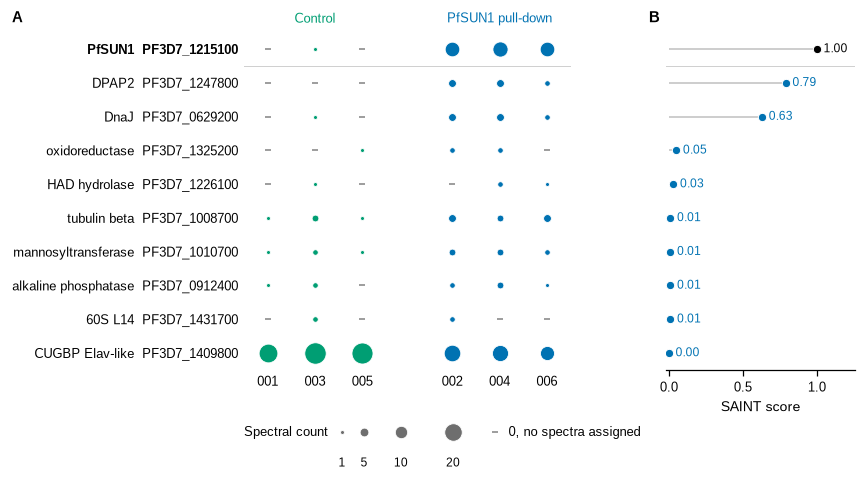

,gene,species,001,003,005,002,004,006,saint_score,bfdr
537,PF3D7_1215100,P. falciparum,0,1,0,14,15,14,1.00,0.00
529,PF3D7_1247800,P. falciparum,0,0,0,4,4,2,0.79,0.00
447,PF3D7_0629200,P. falciparum,0,1,0,4,4,2,0.63,0.11
542,PF3D7_1325200,P. falciparum,0,0,1,2,2,0,0.05,0.73
534,PF3D7_1226100,P. falciparum,0,1,0,0,2,1,0.03,0.77
128,PF3D7_1008700,P. falciparum,1,3,1,4,3,4,0.01,0.90
395,PF3D7_1010700,P. falciparum,1,2,1,3,3,2,0.01,0.91
221,PF3D7_0912400,P. falciparum,1,2,0,2,3,1,0.01,0.88
552,PF3D7_1431700,P. falciparum,0,2,0,2,0,0,0.01,0.89
1,PF3D7_1409800,P. falciparum,23,30,29,18,17,13,0.00,0.97


In [24]:
candidate_map("11_candidate_evidence_parasite",
              score[IS_PARASITE].nlargest(CANDIDATE_ROWS).index)

**Figure 11. SAINTexpress evidence for parasite proteins** This figure shows the same measurements, restricted to P. falciparum proteins. SAINT scores drop sharply after PfSUN1, DPAP2 and DnaJ. The next protein scores only 0.05. Some abundant parasite proteins receive scores close to zero because they are also consistently detected in the controls. The SAINTexpress results differ from the intensity-based analysis in Section 04. None of the 13 proteins enriched by limma passes the SAINTexpress threshold, largely because these proteins also have substantial spectral counts in the controls. PfSUN1 and DPAP2, meanwhile, could not be tested by limma because of missing intensity measurements. DPAP2 is therefore the strongest non-bait candidate from SAINTexpress, with DnaJ showing weaker evidence. Co-purification alone does not demonstrate direct physical interaction.